# Regime-Shaded Price Chart

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Shades the background of a price chart by the market regime a statistical model infers, here a two-state Markov-switching model of returns (calm vs. turbulent). A lower panel shows the model's probability of being in the turbulent state. Readers see how prices behave inside each regime and how confident the model is, not just where a hand-picked "crisis" began.

## When to use

- Show when volatility or trend regimes switched, and how long they lasted
- Explain a regime-based strategy (risk-on / risk-off, volatility targeting)
- Put a long price history into context without manual annotation

## Avoid when

- The audience will read the shading as a forecast (it is estimated with hindsight)
- The model has not been validated; shading lends false authority
- There are more than 3 regimes (colors and labels stop being readable)

## Alternatives

- Rolling volatility chart
- Drawdown chart
- Event timeline with manual annotations

## Design tips

- Say whether probabilities are smoothed (use all data) or filtered (real-time)
- Shade only when the probability exceeds a stated threshold, e.g. 50%
- Keep the shading light so the price line stays dominant

## Example

Simulated daily returns from a two-regime process (calm: low volatility, slight upward drift; turbulent: high volatility, negative drift). The regimes are then estimated back from the returns with statsmodels' MarkovRegression. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import statsmodels.api as sm

### Data

In [2]:
rng = np.random.default_rng(14)
dates = pd.bdate_range("2017-01-02", periods=1600)
stay = {0: 0.993, 1: 0.975}                      # regime persistence
mu, sigma = {0: 0.0006, 1: -0.0012}, {0: 0.007, 1: 0.022}
state, states = 0, []
for _ in dates:
    states.append(state)
    if rng.random() > stay[state]:
        state = 1 - state
states = np.array(states)
returns = pd.Series([rng.normal(mu[s], sigma[s]) for s in states], index=dates, name="return")
price = 100 * (1 + returns).cumprod()
title = "Index price with model-detected turbulent regimes (simulated)"
returns.describe().round(4)

count    1600.0000
mean        0.0003
std         0.0141
min        -0.0686
25%        -0.0062
50%         0.0008
75%         0.0068
max         0.0798
Name: return, dtype: float64

### Plot

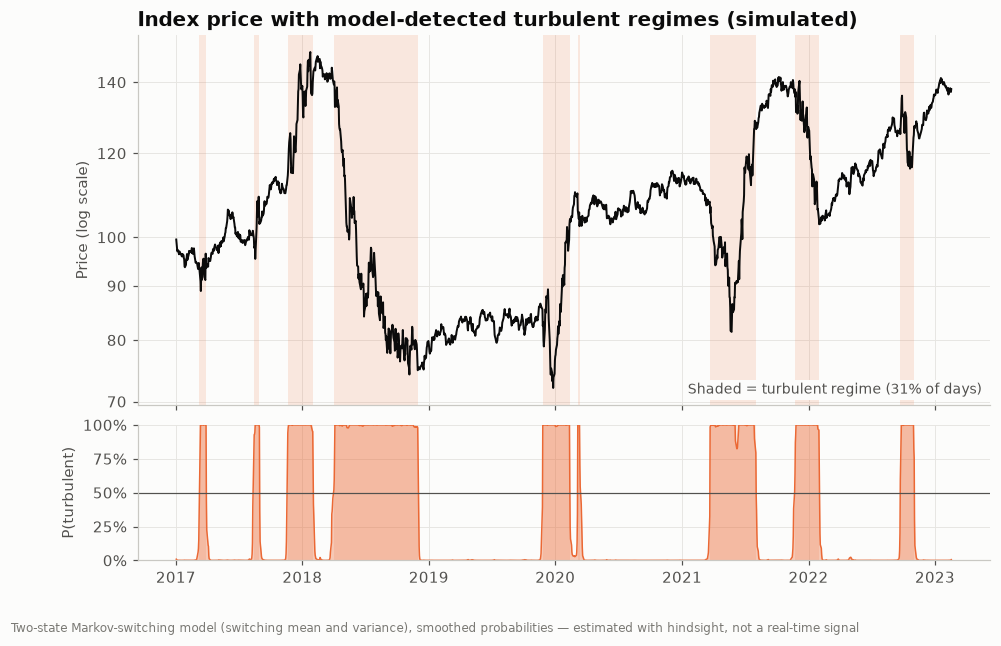

In [3]:
model = sm.tsa.MarkovRegression(returns * 100, k_regimes=2, switching_variance=True)
res = model.fit(disp=False)
variances = [res.params[f"sigma2[{k}]"] for k in range(2)]
p_turb = res.smoothed_marginal_probabilities[int(np.argmax(variances))]
turbulent = p_turb > 0.5

fig, (ax, axp) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.1], "hspace": 0.08})
# shade contiguous turbulent spells
edges = np.flatnonzero(np.diff(np.r_[0, turbulent.astype(int), 0]))
for start, end in zip(edges[::2], edges[1::2]):
    for a in (ax, axp):
        a.axvspan(price.index[start], price.index[end - 1], color=PALETTE[1], alpha=0.14, linewidth=0)
ax.plot(price.index, price, color="#0b0b0b", linewidth=1.3)
ax.set_yscale("log")
lo, hi = price.min(), price.max()
ticks = [v for v in (50, 60, 70, 80, 90, 100, 120, 140, 160, 180, 200, 250, 300) if lo * 0.95 <= v <= hi * 1.05]
ax.yaxis.set_major_locator(plt.FixedLocator(ticks))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_locator(plt.NullLocator())
ax.set_ylabel("Price (log scale)")
ax.set_title(title)
ax.text(0.99, 0.03, f"Shaded = turbulent regime ({turbulent.mean():.0%} of days)",
        transform=ax.transAxes, fontsize=9, color="#52514e", ha="right",
        bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=2))
axp.fill_between(p_turb.index, p_turb, color=PALETTE[1], alpha=0.35, linewidth=0)
axp.plot(p_turb.index, p_turb, color=PALETTE[1], linewidth=1)
axp.axhline(0.5, color="#52514e", linewidth=0.8)
axp.set_ylim(0, 1)
axp.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axp.set_ylabel("P(turbulent)")
fig.text(0.01, 0.005, "Two-state Markov-switching model (switching mean and variance), smoothed probabilities "
         "— estimated with hindsight, not a real-time signal", fontsize=8, color="#7a7974")
plt.show()

## How to read it

Orange bands mark days the model puts more than 50% probability on the turbulent regime. Prices fall and swing widely inside the bands and grind higher outside them. The lower panel shows the probability itself: values near 0 or 1 mean the model is confident, values in between mean it is not.

---
Standalone script: [`regime_shading.py`](regime_shading.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)